# Seed Quality Classification + XAI — Single GPU, Accuracy-Focused
**EfficientNet-B2 | Kaggle GPU | Classes:** `broken`, `discolored`, `pure`, `silkcut`

This experiment uses unweighted cross-entropy and saves the checkpoint with the highest validation accuracy. Run cells from top to bottom. Keep `USE_GAN = False` for a real-data baseline. Training prints one summary line per epoch with elapsed time.

## Cell 1 — Imports and configuration

In [14]:
import os, time, copy, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
from torch import nn
from torch.utils.data import DataLoader, ConcatDataset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

TRAIN_DIR = "/kaggle/input/datasets/bmuthukumar07/seed-data/data/train"
VAL_DIR = "/kaggle/input/datasets/bmuthukumar07/seed-data/data/val"
if not os.path.isdir(VAL_DIR):
    VAL_DIR = "/kaggle/input/datasets/bmuthukumar07/seed-data/data/validation"
GAN_DIR = "/kaggle/input/datasets/bmuthukumar07/gan-seed-data/seed_augmented"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
EPOCHS = 15
PATIENCE = 5
LR = 1e-4
USE_GAN = False

print("Train directory exists:", os.path.isdir(TRAIN_DIR))
print("Validation directory exists:", os.path.isdir(VAL_DIR))
print("Optional GAN directory exists:", os.path.isdir(GAN_DIR))

Device: cuda
GPU: Tesla T4
Train directory exists: True
Validation directory exists: True
Optional GAN directory exists: True


## Cell 2 — Image transforms

In [15]:
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.08
    ),
    transforms.ToTensor(),
    normalize
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    normalize
])

print("Transforms ready.")

Transforms ready.


## Cell 3 — Load train and validation datasets

In [16]:
train_real = datasets.ImageFolder(TRAIN_DIR, transform=train_tfms)
val_ds = datasets.ImageFolder(VAL_DIR, transform=eval_tfms)

class_names = train_real.classes
num_classes = len(class_names)

assert num_classes == 4, f"Expected 4 classes, found {class_names}"
assert val_ds.classes == class_names, (
    f"Train classes {class_names} differ from validation classes {val_ds.classes}"
)

train_ds = train_real
gan_ds = None

if USE_GAN:
    if not os.path.isdir(GAN_DIR):
        raise FileNotFoundError(f"GAN directory not found: {GAN_DIR}")
    gan_ds = datasets.ImageFolder(GAN_DIR, transform=train_tfms)
    assert gan_ds.classes == class_names, (
        f"GAN classes {gan_ds.classes} differ from train classes {class_names}"
    )
    train_ds = ConcatDataset([train_real, gan_ds])

print("Classes:", class_names)
print("Real train images:", len(train_real))
print("Validation images:", len(val_ds))
print("GAN images:", len(gan_ds) if gan_ds is not None else 0)

Classes: ['broken', 'discolored', 'pure', 'silkcut']
Real train images: 14340
Validation images: 3479
GAN images: 0


## Cell 4 — Create DataLoaders (single GPU)

In [17]:
if USE_GAN and gan_ds is not None:
    sample_weights = np.concatenate([
        np.ones(len(train_real), dtype=np.float64),
        np.full(len(gan_ds), GAN_WEIGHT, dtype=np.float64)
    ])
    sampler = WeightedRandomSampler(
        torch.as_tensor(sample_weights, dtype=torch.double),
        num_samples=len(train_ds),
        replacement=True
    )
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, sampler=sampler,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )
else:
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
        persistent_workers=(NUM_WORKERS > 0)
    )

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 449
Validation batches: 109


## Cell 5 — Build EfficientNet-B2

In [19]:
model = models.efficientnet_b2(
    weights=models.EfficientNet_B2_Weights.DEFAULT
)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(class_names)
)

model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

# 7. Mixed precision
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# 8. Verify trainable parameters
trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable:,} / {total:,}")
print(f"Trainable percentage: {100 * trainable / total:.2f}%")

print("Model ready on:", device)
print("Loss: unweighted CrossEntropyLoss")
print("Checkpoint selection: highest validation accuracy")

Trainable parameters: 7,706,630 / 7,706,630
Trainable percentage: 100.00%
Model ready on: cuda
Loss: unweighted CrossEntropyLoss
Checkpoint selection: highest validation accuracy


## Cell 6 — Define one training/validation epoch

In [20]:
def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    all_labels, all_preds = [], []

    with (torch.enable_grad() if training else torch.no_grad()):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            total_loss += loss.item() * images.size(0)
            all_labels.extend(labels.detach().cpu().numpy())
            all_preds.extend(outputs.argmax(1).detach().cpu().numpy())

    return total_loss / len(loader.dataset), accuracy_score(all_labels, all_preds)

## Cell 7 — Train with early stopping

In [21]:
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}
best_val_acc = -1.0
best_state = copy.deepcopy(model.state_dict())
wait = 0
PATIENCE = 5
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    scheduler.step()
    epoch_time = (time.time() - epoch_start) / 60

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train loss={train_loss:.4f}, acc={train_acc:.4f} | "
        f"Val loss={val_loss:.4f}, acc={val_acc:.4f} | "
        f"Time: {epoch_time:.2f} min"
    )

    # Save best validation-accuracy checkpoint.
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "/kaggle/working/best_seed_efficientnet_b2.pth")
        wait = 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stopping after epoch {epoch}.")
            break

model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_val_acc:.4f}")
print(f"Total training time: {(time.time()-training_start)/60:.2f} min")
print("Best checkpoint saved to /kaggle/working/best_seed_efficientnet_b2.pth")

Epoch 1/15 | Train loss=0.8770, acc=0.6696 | Val loss=0.7098, acc=0.7540 | Time: 1.33 min
Epoch 2/15 | Train loss=0.6864, acc=0.7667 | Val loss=0.6560, acc=0.7790 | Time: 1.09 min
Epoch 3/15 | Train loss=0.6148, acc=0.8046 | Val loss=0.6717, acc=0.7735 | Time: 1.08 min
Epoch 4/15 | Train loss=0.5687, acc=0.8268 | Val loss=0.6589, acc=0.7818 | Time: 1.09 min
Epoch 5/15 | Train loss=0.5128, acc=0.8548 | Val loss=0.6870, acc=0.7787 | Time: 1.10 min
Epoch 6/15 | Train loss=0.4744, acc=0.8745 | Val loss=0.6908, acc=0.7850 | Time: 1.09 min
Epoch 8/15 | Train loss=0.3797, acc=0.9250 | Val loss=0.7519, acc=0.7729 | Time: 1.08 min
Epoch 9/15 | Train loss=0.3543, acc=0.9382 | Val loss=0.7529, acc=0.7761 | Time: 1.08 min
Epoch 10/15 | Train loss=0.3332, acc=0.9475 | Val loss=0.7631, acc=0.7790 | Time: 1.08 min
Epoch 11/15 | Train loss=0.3156, acc=0.9567 | Val loss=0.7753, acc=0.7749 | Time: 1.08 min
Early stopping after epoch 11.
Best validation accuracy: 0.7850
Total training time: 12.20 min
Bes

## Cell 8 — Plot training curves

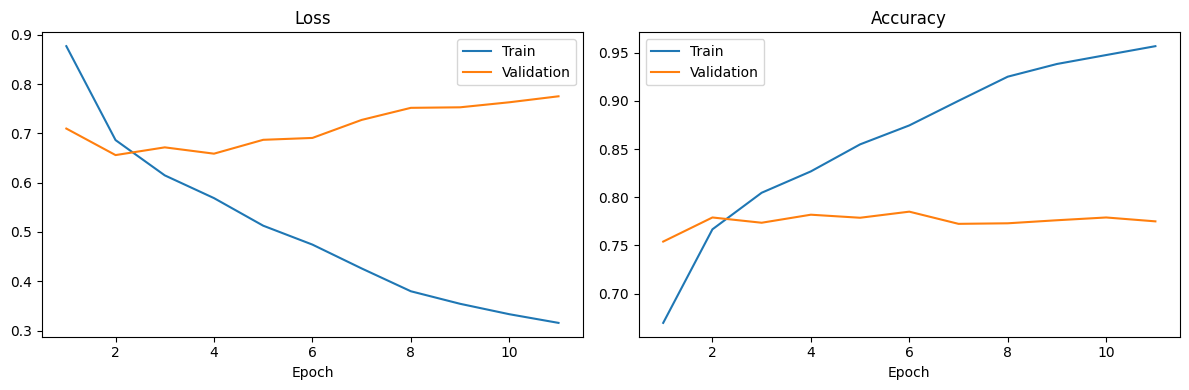

In [22]:
epochs_ran = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_ran, history["train_loss"], label="Train")
axes[0].plot(epochs_ran, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_ran, history["train_acc"], label="Train")
axes[1].plot(epochs_ran, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## Cell 9 — Evaluate and plot confusion matrix + ROC

Validation accuracy: 0.785
              precision    recall  f1-score   support

      broken     0.7823    0.7375    0.7592      1116
  discolored     0.7026    0.6612    0.6813       611
        pure     0.8286    0.8768    0.8520      1428
     silkcut     0.7390    0.7778    0.7579       324

    accuracy                         0.7850      3479
   macro avg     0.7631    0.7633    0.7626      3479
weighted avg     0.7833    0.7850    0.7835      3479



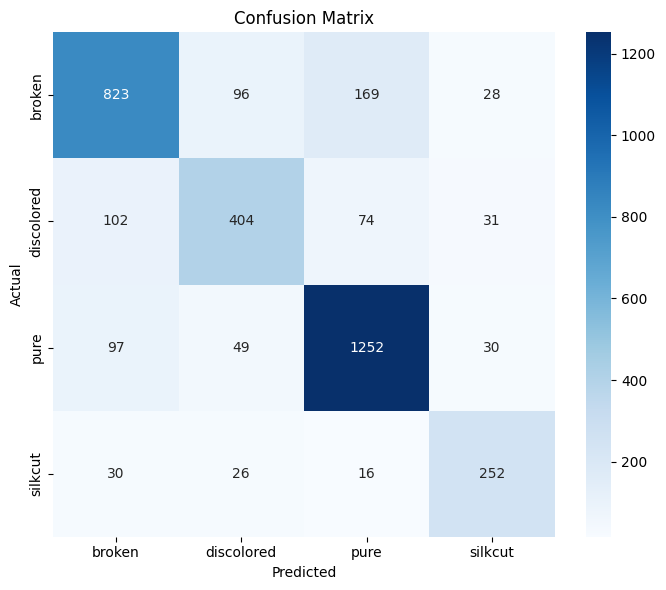

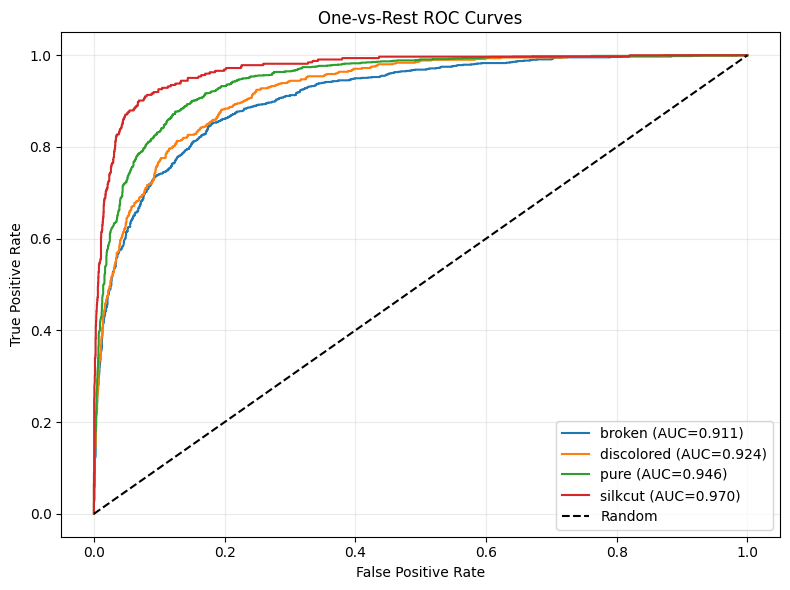

In [23]:
model.load_state_dict(torch.load("/kaggle/working/best_seed_efficientnet_b2.pth", map_location=device, weights_only=True))
model.eval()
y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(images)
        probs = torch.softmax(logits, dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(probs.argmax(1).cpu().numpy())
        y_prob.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Validation accuracy:", round(accuracy_score(y_true, y_pred), 4))
print(classification_report(
    y_true, y_pred, target_names=class_names, digits=4, zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

y_bin = label_binarize(y_true, classes=np.arange(num_classes))
plt.figure(figsize=(8, 6))
for i, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Cell 10 — Grad-CAM XAI

In [ ]:
target_layer = model.features[-1]
cam_cache = {"activations": None, "gradients": None}

def save_activation(module, inputs, output):
    cam_cache["activations"] = output

def save_gradient(module, grad_input, grad_output):
    cam_cache["gradients"] = grad_output[0]

hook1 = target_layer.register_forward_hook(save_activation)
hook2 = target_layer.register_full_backward_hook(save_gradient)

def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406], device=tensor.device).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=tensor.device).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)

def make_gradcam(image_tensor):
    model.eval()
    x = image_tensor.unsqueeze(0).to(device)
    model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        logits = model(x)
        predicted_class = int(logits.argmax(dim=1).item())
        logits[0, predicted_class].backward()

    activations = cam_cache["activations"].detach()
    gradients = cam_cache["gradients"].detach()
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(
        cam, size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear", align_corners=False
    )[0, 0]
    cam = cam.cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    probabilities = torch.softmax(logits.detach(), dim=1)[0].cpu().numpy()
    return cam, predicted_class, probabilities

n_show = min(6, len(val_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(11, 4 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n_show):
    image_tensor, true_label = val_ds[i]
    cam, pred_label, probs = make_gradcam(image_tensor)
    image = denormalize(image_tensor.to(device)).permute(1, 2, 0).cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original | True: {class_names[true_label]}")
    axes[i, 1].imshow(cam, cmap="jet")
    axes[i, 1].set_title("Grad-CAM heatmap")
    axes[i, 2].imshow(image)
    axes[i, 2].imshow(cam, cmap="jet", alpha=0.4)
    axes[i, 2].set_title(f"Overlay | Pred: {class_names[pred_label]} ({probs[pred_label]:.2f})")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()
hook1.remove()
hook2.remove()

## Cell 11 — Visualize misclassified images

In [ ]:
wrong_indices = np.where(y_true != y_pred)[0]
print("Misclassified:", len(wrong_indices), "of", len(y_true))

n_show = min(8, len(wrong_indices))
if n_show:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, wrong_indices[:n_show]):
        image_tensor, true_label = val_ds[int(idx)]
        image = denormalize(image_tensor.to(device)).permute(1, 2, 0).cpu().numpy()
        ax.imshow(image)
        ax.set_title(f"True: {class_names[true_label]}\\nPred: {class_names[y_pred[idx]]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Cell 12 — Save final checkpoint

In [ ]:
checkpoint_path = "/kaggle/working/seed_classifier_checkpoint.pth"
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "img_size": IMG_SIZE
}, checkpoint_path)
print("Saved:", checkpoint_path)

## Cell 13 — Predict a new image (optional)

In [ ]:
def predict_image(image_path):
    image = Image.open(image_path).convert("RGB")
    tensor = eval_tfms(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(tensor)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    order = np.argsort(probs)[::-1]
    for idx in order:
        print(f"{class_names[idx]}: {probs[idx]:.4f}")

    plt.figure(figsize=(4, 4))
    plt.imshow(image.resize((IMG_SIZE, IMG_SIZE)))
    plt.title(f"Prediction: {class_names[order[0]]} ({probs[order[0]]:.2%})")
    plt.axis("off")
    plt.show()
    return class_names[order[0]], probs

# Example:
# predict_image("/kaggle/input/your-dataset/example.jpg")